In [1]:
import iris
import numpy as np
import sys
import subprocess
import matplotlib.pyplot as plt
import scipy
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.interpolate import RegularGridInterpolator
from iris.analysis import trajectory
from iris.analysis.cartography import rotate_pole
from matplotlib.colors import TwoSlopeNorm

from datetime import datetime

sys.path.append("/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/")

data_path_base = "/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/"

data_dir = f"{data_path_base}/momentum_fluxes/sonde_flux_arrays_entire_wEOP"

data_files_raw = sorted(Path(data_dir).glob("*.npz"))

data_files_raw



[PosixPath('/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/sonde_flux_arrays_entire_wEOP/202501272039_S0250198_STERZING_NCAS_v2.0.TPB_0_Momentum_Flux_model.npz'),
 PosixPath('/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/sonde_flux_arrays_entire_wEOP/202501272300_S0250181_STERZING_NCAS_v2.0.TPB_1_Momentum_Flux_model.npz'),
 PosixPath('/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/sonde_flux_arrays_entire_wEOP/202501272300_S0250182_STERZING_NCAS_v2.0.TPB_2_Momentum_Flux_model.npz'),
 PosixPath('/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/sonde_flux_arrays_entire_wEOP/202501280200_S0250132_STERZING_NCAS_v2.0.TPB_3_Momentum_Flux_model.npz'),
 PosixPath('/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/sonde_flux_arrays_entire_wEOP/202501280200_S0250183_STERZING_NCAS_v2.0.TPB_4_Momentum_Flu

In [ ]:
# =============================================================================
# CONSTRUCT THE TEMPORAL COORDINATES FOR THE RADIOSONDE DATASET
# =============================================================================

# Extract the launch timestamps from the filenames of the saved flux arrays.
# These establish the chronological distribution of radiosonde observations
# across the observational period.
dates_list = []
for i in data_files_raw:
    name = i.stem
    date = name[0:12]
    date = datetime.strptime(date, "%Y%m%d%H%M")
    dates_list.append(date)
    
dates_array = np.array(dates_list)

# Calculate the time separation between consecutive radiosonde launches.
# hours_diff contains these intervals in hours, providing information
# about the temporal sampling of the dataset.
time_diffs = np.diff(dates_array)

hours_diff = np.zeros_like(time_diffs)

for i in range(0, len(time_diffs)):
    hours_diff[i] = round(time_diffs[i].total_seconds()/3600,2)

# Express each launch time as the number of days elapsed since the first
# radiosonde observation. This establishes a common relative time coordinate
# for subsequent analysis and visualisation.
time_passed = np.zeros_like(dates_array)

# Take the difference, in days, from first sonde:
for i in range(0, len(dates_array)):
    datetime_diff = dates_array[i] - dates_array[0]
    time_passed[i] = float((datetime_diff.total_seconds())/(3600*24))

# Dual sondes have identical or nearly identical recorded launch times.
# Introduce a small offset between consecutive dual sonde
# launches, allowing them to occupy distinct
# positions along the time axis.
#
# These offsets are artificial and do not represent measured launch times.
t = time_passed.copy()

epsilon = 1 / (24 * 3600)   # 1 second, expressed in days

# Record the indices of observations whose timestamps have been adjusted.
# These indices can also be used to identify observations for exclusion
# if only one radiosonde per launch time is required.
second_dual_sonde_idx = []

for i in range(1, len(t)):
    if np.isclose(time_passed[i], time_passed[i - 1]):
        t[i] = float(t[i - 1] + epsilon)
        second_dual_sonde_idx.append(i)

# Final time coordinate, expressed in elapsed days from the first launch.
# Each entry corresponds to the radiosonde at the same index in data_files_raw.
sonde_times = np.asarray(t, dtype=float)

# Retain all radiosonde files, including observations with matching timestamps.
# The alternative, currently disabled, would exclude observations whose
# timestamps were adjusted above.
#data_files = [file for i, file in enumerate(data_files_raw) if i not in second_dual_sonde_idx]
data_files = data_files_raw


# Optional inspection of the original launch timestamps.
# for i,j in enumerate(dates_list):
#    print(f"{j}")


In [ ]:
# =============================================================================
# DEFINE INTENSIVE OBSERVATION PERIOD (IOP) BOUNDARIES
# =============================================================================

# Identify the ranges of radiosonde indices corresponding to each IOP.
# These boundaries will be used to distinguish the different observation
# periods in subsequent plots, including the placement of vertical markers.
#
# The indices correspond to the complete radiosonde dataset, including
# observations with duplicate launch timestamps.

# Including all double sondes, uncomment if keeping all double sondes
iop_starts = [0, 12, 30, 39, 58, 80, 97, 126, 133]
iop_ends = [11, 27, 35, 48, 73, 90, 104, 131, 140]

# Combine the start and end indices into a list of IOP intervals.
# Each tuple identifies the range of observations belonging to one IOP.
iop_windows = [(iop_starts[i], iop_ends[i]) for i in range(0, len(iop_starts))]

# Assign the corresponding IOP identifiers to these intervals.
# These labels can be used to identify each observational period in plots.
iop_tick_labels = ["2", "3", "5", "7", "10", "11", "12", "17", "18"] 

# Calculate the span of each IOP in radiosonde index units.
# These are index differences, not elapsed times or observation counts.
iop_width = [i[1] - i[0] for i in iop_windows]

# Determine the midpoint of each IOP's index range.
# These positions can be used to centre IOP labels on subsequent plots.
iop_ticks = [0.5*(iop_starts[i] + iop_ends[i]) for i in range(0, len(iop_starts))]



In [ ]:
# Load in the flux data. 
# For the purposes of this script we are using the 
# coarsened sondes, i.e. raw sonde data 
# coarsened to model levels. This can be swapped for model data
# once simulations for the entire EOP (or an extended collection of
# IOPs) are ready. 

alts_list = []
flux_u_s_list = []
flux_v_s_list = []


for i in data_files:    
    alts_list.append(np.load(i)["alt_s_km"])
    flux_u_s_list.append(np.load(i)["Flux_u_s"])
    flux_v_s_list.append(np.load(i)["Flux_v_s"]) 
 


In [ ]:
# This is the median number of samples from all the sondes in the lists above
# All other sondes will get sampled accordingly
median_len = int(np.median([len(i) for i in alts_list]))
max_alt_idx = np.argmax([np.nanmax(i) for i in alts_list])

indices_list = []
for i in alts_list:
    indices_list.append(np.linspace(0, len(i)-1 , median_len, dtype=int))

sampled_alts_list = []
sampled_flux_u_s_list = []
sampled_flux_v_s_list = []

for i,j in enumerate(alts_list):    
    sampled_alts_list.append(alts_list[i][indices_list[i]])
    sampled_flux_u_s_list.append(flux_u_s_list[i][indices_list[i]])
    sampled_flux_v_s_list.append(flux_v_s_list[i][indices_list[i]])





In [6]:
# Now try to produce the heatmap array for each variable
# First step is to produce the relevant arrays
Fluxes_u_s = np.array(sampled_flux_u_s_list)
Fluxes_v_s = np.array(sampled_flux_v_s_list)

# Alt will be the y axis
alt = sampled_alts_list[max_alt_idx]

# Horizontal axis will be an index from 0 to length of data_list
x_axis = np.arange(0, len(data_files),1)
#x_axis = sonde_times

# Now create the grid
x, alts_y = np.meshgrid(x_axis, alt, indexing="ij")



In [ ]:
# =============================================================================
# FILTER EXTREME MOMENTUM FLUX VALUES
# =============================================================================

# Exclude the most extreme zonal and meridional momentum flux estimates
# from the sonde dataset before subsequent analysis and visualisation.
#
# The 1st and 99th percentiles are calculated independently for each
# component, using all valid values in the corresponding flux array.
#
# Values outside these limits are replaced with NaNs, preserving the
# original array dimensions and the correspondence between flux values,
# radiosonde indices, and altitude coordinates.
#
# The original flux arrays remain unchanged. The filtered arrays retain
# approximately the central 98% of valid values for each component.

# Filter zonal momentum flux.
lower_u = np.nanpercentile(Fluxes_u_s, 1)
upper_u = np.nanpercentile(Fluxes_u_s, 99)

quartile_mask_u = (Fluxes_u_s >= lower_u) & (Fluxes_u_s <= upper_u)

Fluxes_u_s_filtered = Fluxes_u_s.copy()

Fluxes_u_s_filtered[~quartile_mask_u] = np.nan

# Filter meridional momentum flux independently.
# The retained positions need not coincide with those of the zonal flux.
lower_v = np.nanpercentile(Fluxes_v_s, 1)
upper_v = np.nanpercentile(Fluxes_v_s, 99)

quartile_mask_v = (Fluxes_v_s >= lower_v) & (Fluxes_v_s <= upper_v)

Fluxes_v_s_filtered = Fluxes_v_s.copy()

Fluxes_v_s_filtered[~quartile_mask_v] = np.nan

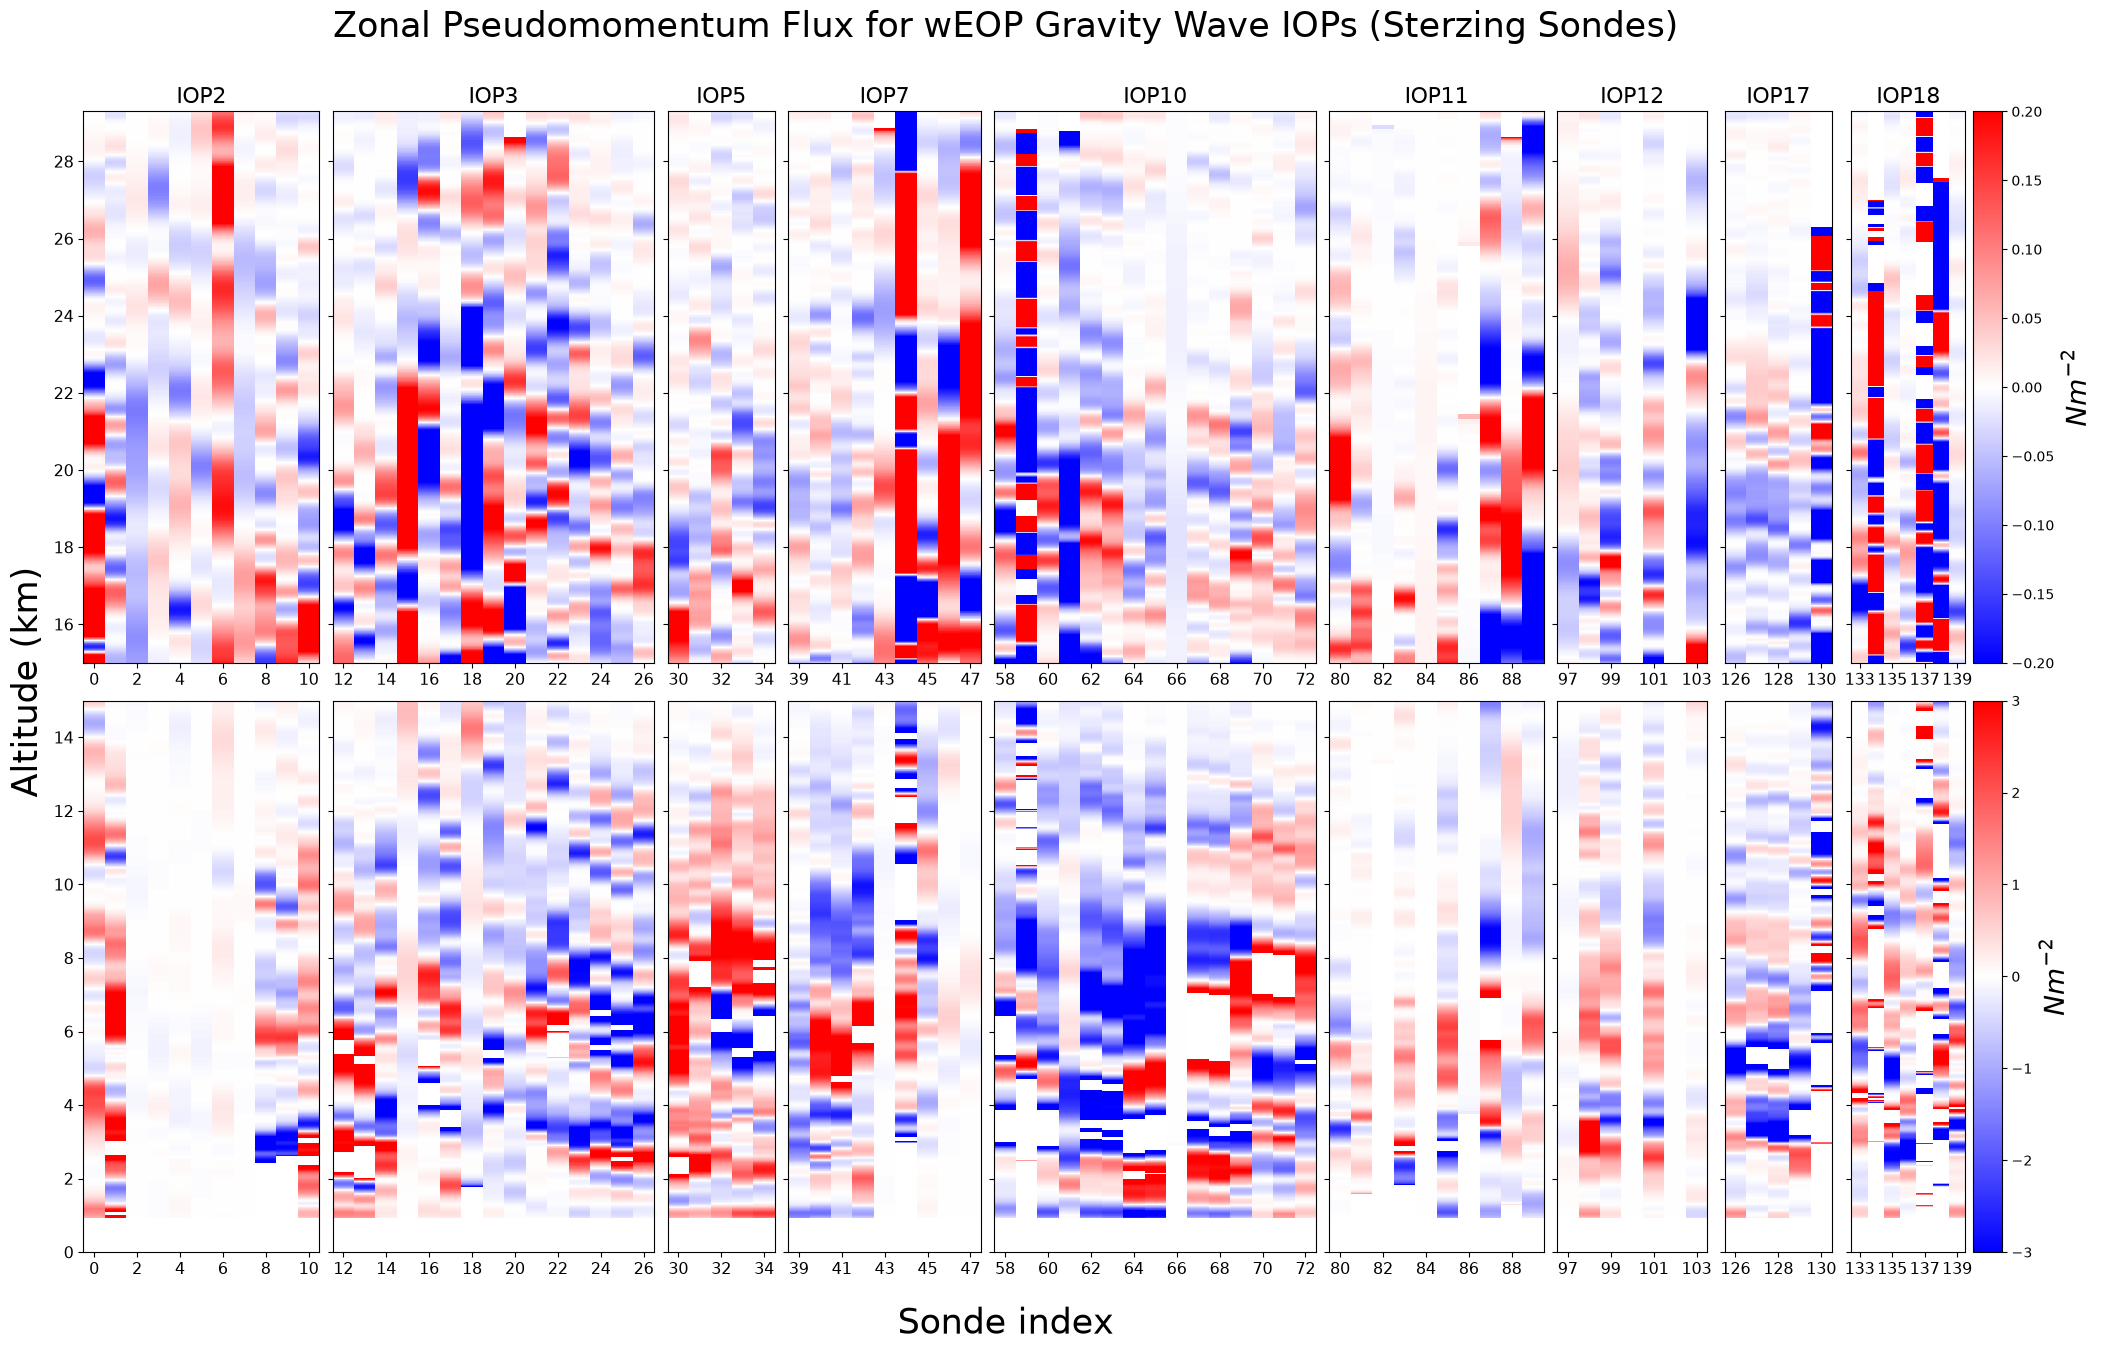

In [24]:
# Now same plot as above, but split for below and above 15 km

fig = plt.figure(figsize=(20, 12), layout="constrained")
axes = fig.subplots(2, len(iop_windows), sharey="row", gridspec_kw={"width_ratios":iop_width})

# Centre the colorbar
norm_1 = TwoSlopeNorm(vmin=-0.2, vmax=0.2, vcenter=0)
cmap_1 = "bwr"
ylim_1 = (15, None)

# Plot the zonal component upper half
for ax, (start, end), label in zip(axes[0], iop_windows, iop_tick_labels):
    s = np.s_[start: end: , :: ]
    s_ticks = np.s_[start:end:2,::]
    plot_1 = ax.pcolormesh(x[s], alts_y[s], Fluxes_u_s_filtered[s], cmap=cmap_1, norm=norm_1)
    ax.set_title(f"IOP{label}", fontsize=16)
    # Set up x axis
    ax.set_xticks([int(i[0]) for i in x[s_ticks]])
    # Set up y axis
    ax.set_ylim(ylim_1)
    ax.tick_params(axis="x", labelsize=11.5)
    ax.tick_params(axis="y", labelsize=11.5)


# Centre the colorbar
norm_2 = TwoSlopeNorm(vmin=-3, vmax=3, vcenter=0)
cmap_2 = "bwr"
ylim_2 = (0, 15)

for ax, (start, end), label in zip(axes[1], iop_windows, iop_tick_labels):
    s = np.s_[start:end:,::]
    s_ticks = np.s_[start:end:2,::]
    plot_2 = ax.pcolormesh(x[s], alts_y[s], Fluxes_u_s_filtered[s], cmap=cmap_2, norm=norm_2)
    #ax.set_title(f"IOP{label}")
    # Set up x axis
    ax.set_xticks([int(i[0]) for i in x[s_ticks]])
    # Set up y axis
    ax.set_ylim(ylim_2)
    ax.tick_params(axis="x", labelsize=11.5)
    ax.tick_params(axis="y", labelsize=11.5)


# axes[0][0].set_ylabel(f"Altitude 15km to 30km")``
# axes[1][0].set_ylabel(f"Altitude 0km to 15km")

from mpl_toolkits.axes_grid1 import make_axes_locatable

# Upper colourbar
divider_upper = make_axes_locatable(axes[0][-1])
cax_upper = divider_upper.append_axes("right", size="25%", pad=0.08)

cbar_upper = fig.colorbar(plot_1, cax=cax_upper)
cbar_upper.set_label(r"$Nm^{-2}$", fontsize=20)


# Lower colourbar
divider_lower = make_axes_locatable(axes[1][-1])
cax_lower = divider_lower.append_axes("right", size="25%", pad=0.08)

cbar_lower = fig.colorbar(plot_2, cax=cax_lower)
cbar_lower.set_label(r"$Nm^{-2}$", fontsize=20)

fig.suptitle("Zonal Pseudomomentum Flux for wEOP Gravity Wave IOPs (Sterzing Sondes)", y=1.06, fontsize=25)
fig.supxlabel("Sonde index", y=-0.05, fontsize=25)
fig.supylabel("Altitude (km)", fontsize=25)


fig.savefig("entire_eop_zonal_flux.png", dpi=1000, bbox_inches="tight")

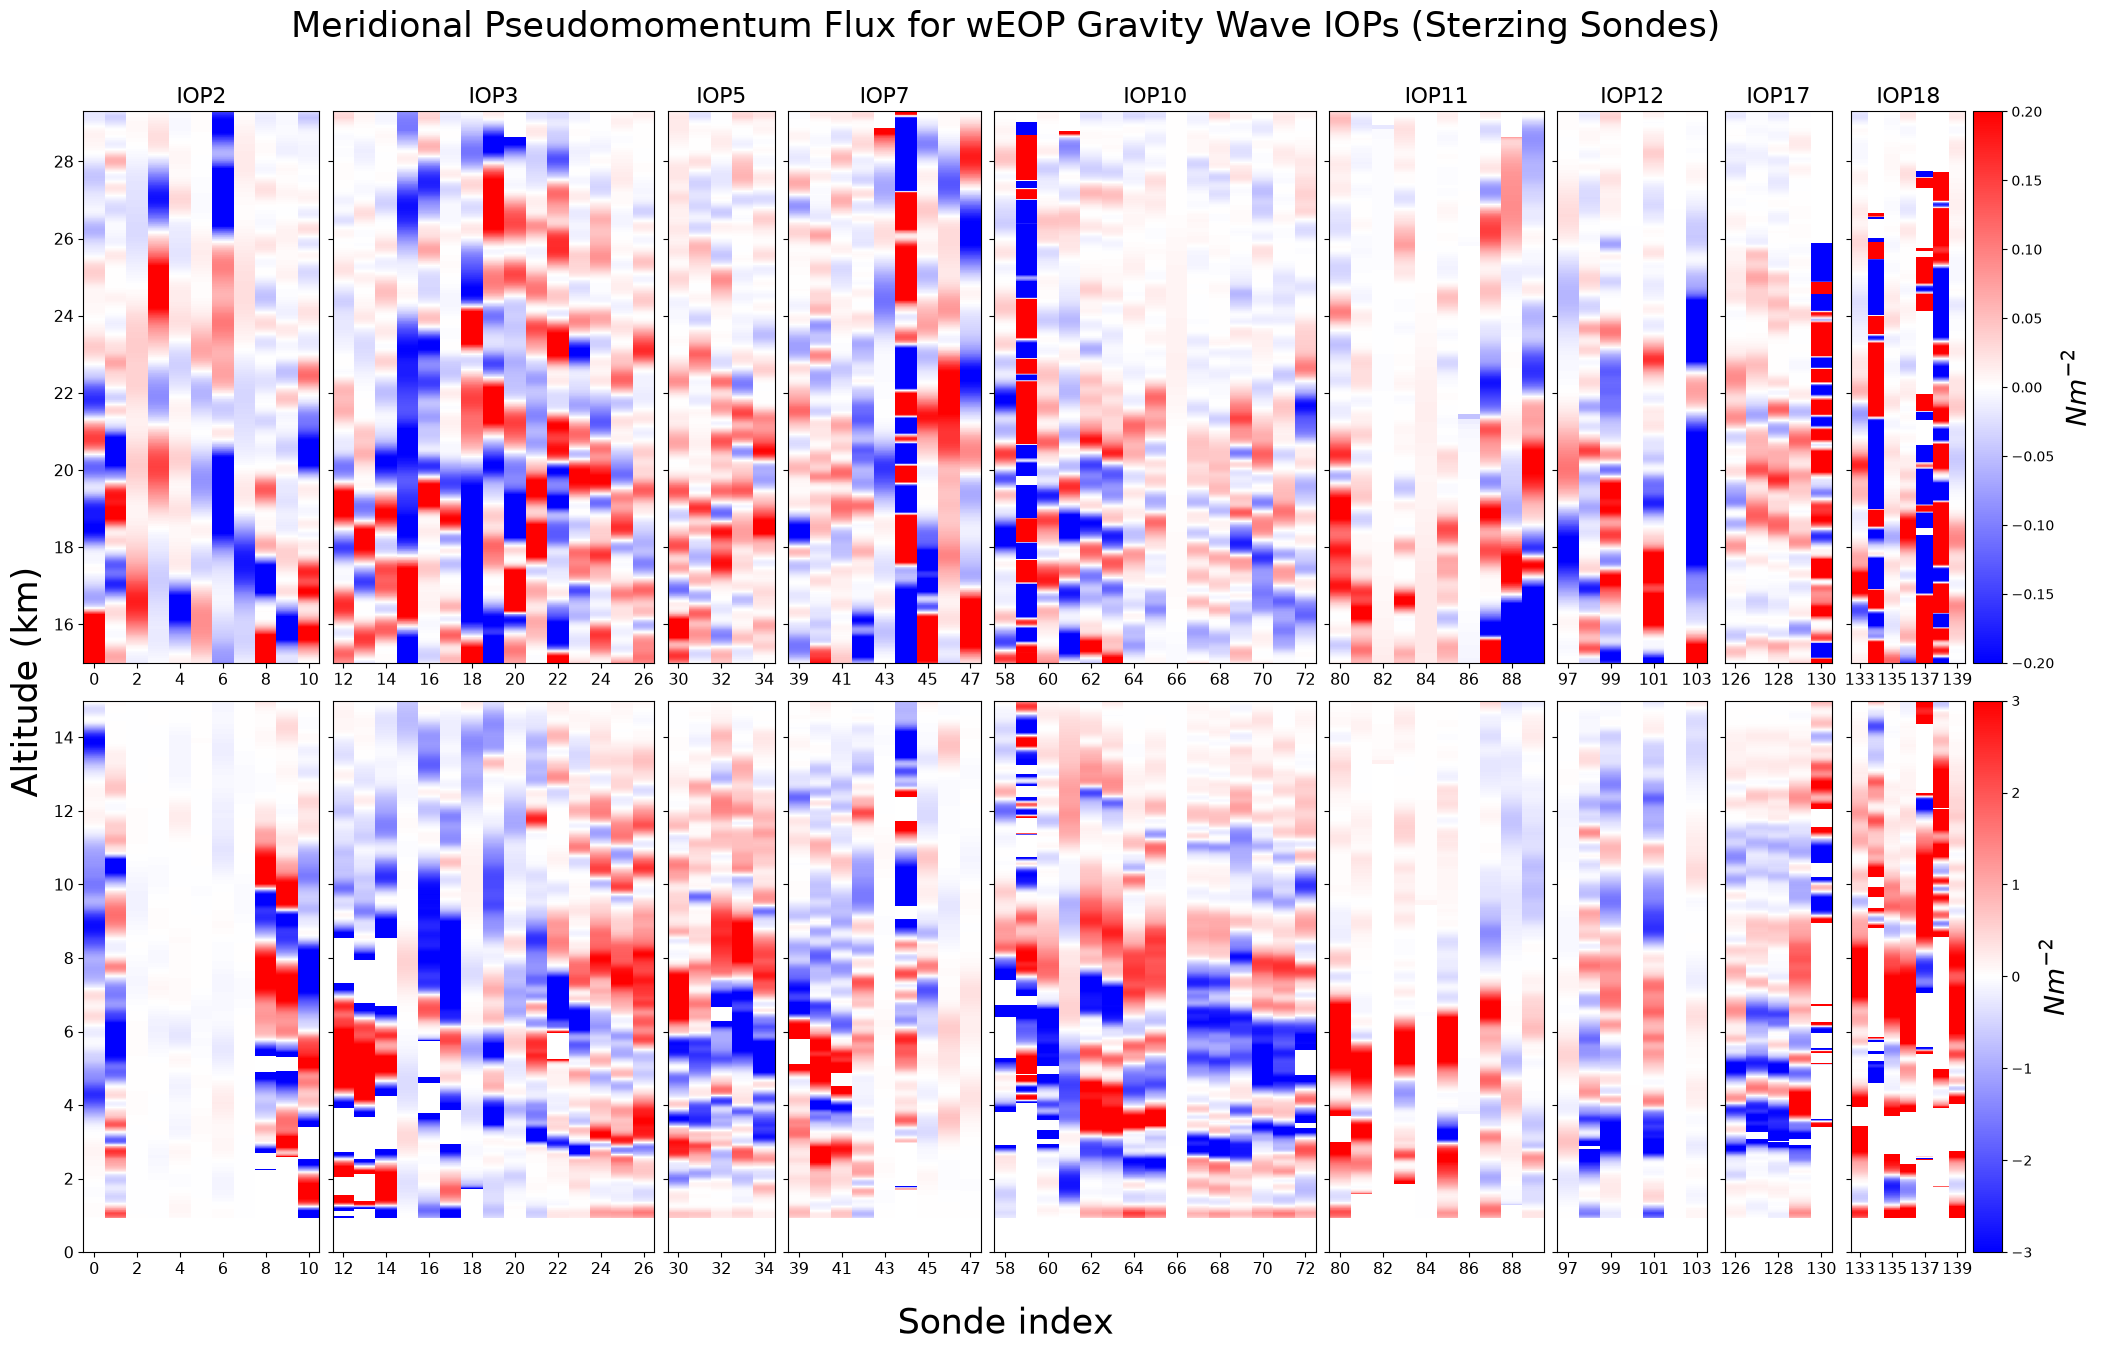

In [25]:
# Meridional Flux, above and below 15 km 

fig = plt.figure(figsize=(20, 12), layout="constrained")
axes = fig.subplots(2, len(iop_windows), sharey="row", gridspec_kw={"width_ratios":iop_width})

# Centre the colorbar
norm_1 = TwoSlopeNorm(vmin=-0.2, vmax=0.2, vcenter=0)
cmap_1 = "bwr"
ylim_1 = (15, None)

# Plot the zonal component upper half
for ax, (start, end), label in zip(axes[0], iop_windows, iop_tick_labels):
    s = np.s_[start: end: , :: ]
    s_ticks = np.s_[start:end:2,::]
    plot_1 = ax.pcolormesh(x[s], alts_y[s], Fluxes_v_s_filtered[s], cmap=cmap_1, norm=norm_1)
    ax.set_title(f"IOP{label}", fontsize=16)
    # Set up x axis
    ax.set_xticks([int(i[0]) for i in x[s_ticks]])
    ax.tick_params(axis="x", labelsize=11.5)
    ax.tick_params(axis="y", labelsize=11.5)
    # Set up y axis
    ax.set_ylim(ylim_1)


# Centre the colorbar
norm_2 = TwoSlopeNorm(vmin=-3, vmax=3, vcenter=0)
cmap_2 = "bwr"
ylim_2 = (0, 15)

# Plot the meridional component lower half
for ax, (start, end), label in zip(axes[1], iop_windows, iop_tick_labels):
    s = np.s_[start:end:,::]
    s_ticks = np.s_[start:end:2,::]
    plot_2 = ax.pcolormesh(x[s], alts_y[s], Fluxes_v_s_filtered[s], cmap=cmap_2, norm=norm_2)
    #ax.set_title(f"IOP{label}")
    # Set up x axis
    ax.set_xticks([int(i[0]) for i in x[s_ticks]])
    # Set up y axis
    ax.set_ylim(ylim_2)
    ax.tick_params(axis="x", labelsize=11.5)
    ax.tick_params(axis="y", labelsize=11.5)


# axes[0][0].set_ylabel(f"Altitude 15km to 30km")``
# axes[1][0].set_ylabel(f"Altitude 0km to 15km")

from mpl_toolkits.axes_grid1 import make_axes_locatable

# Upper colourbar
divider_upper = make_axes_locatable(axes[0][-1])
cax_upper = divider_upper.append_axes("right", size="25%", pad=0.08)

cbar_upper = fig.colorbar(plot_1, cax=cax_upper)
cbar_upper.set_label(r"$Nm^{-2}$", fontsize=20)


# Lower colourbar
divider_lower = make_axes_locatable(axes[1][-1])
cax_lower = divider_lower.append_axes("right", size="25%", pad=0.08)

cbar_lower = fig.colorbar(plot_2, cax=cax_lower)
cbar_lower.set_label(r"$Nm^{-2}$", fontsize=20)

fig.suptitle("Meridional Pseudomomentum Flux for wEOP Gravity Wave IOPs (Sterzing Sondes)", y=1.06, fontsize=25)
fig.supxlabel("Sonde index", y=-0.05, fontsize=25)
fig.supylabel("Altitude (km)", fontsize=25)


fig.savefig("entire_eop_meridional_flux.png", dpi=1000, bbox_inches="tight")